# ML-11 capstone — Ranking candidates for human review

**Lane:** Refresh / Content Opportunity Scoring  
**Author:** Divyam Chauhan  
**Source:** Gated Hugging Face `FlyRank/internship-warehouse`, release/build `v20260703`, table `fact_content_daily_performance`; March 2026 features and April 2026 outcome.

> This is retrospective decision support for editorial review. It does not identify stale pages, establish early-warning ability, estimate refresh lift, or show that editing a page recovers traffic.

## 1. Question and decision

Among page-client pairs that pass the ML-07 review gate, how does an L2 Logistic Regression ranking based on March observations compare with the transparent ML-07 rule when held-out units are clients? A human reviewer may use the ordering to choose which eligible items to inspect first; current page, query, coverage, and business context must still be checked before any action.

## 2. Data contract

The `fact_content_daily_performance` table from release/build `v20260703` is aggregated to one page-client pair per month. A pair enters the analysis only with at least 20 days where `gsc_data_available IS TRUE` in both March and April 2026 and positive March impressions. The paired frame has 95,633 items. Because April coverage determines cohort membership, this exact cohort could not have been selected at a March-time decision point; this is a cohort-selection/decision-time limitation, not label leakage.

The outcome is April impressions at most 80% of March impressions. It is a retrospective next-month decline proxy, not a refresh-success label. The ML-07 gate requires at least 500 March impressions, average position above 0 and at most 20, and CTR below 0.5%. It selects 39,545 candidates across 31 client groups. All model and rule results are conditional on that pool.

In [1]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display

repo_root = Path.cwd()
while not (repo_root / '.env').is_file() and repo_root != repo_root.parent:
    repo_root = repo_root.parent
if not (repo_root / '.env').is_file():
    raise FileNotFoundError('Repository-root .env with HF_TOKEN is required; credential is never displayed.')
hf_token = None
for line in (repo_root / '.env').read_text(encoding='utf-8').splitlines():
    if '=' in line and not line.lstrip().startswith('#'):
        key, value = line.split('=', 1)
        if key.strip() == 'HF_TOKEN':
            hf_token = value.strip().strip(chr(34)).strip(chr(39))
            break
if not hf_token or not hf_token.startswith('hf_'):
    raise ValueError('HF_TOKEN is missing or malformed; credential is never displayed.')
con = duckdb.connect()
con.execute('LOAD httpfs')
con.execute('CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN ?)', [hf_token])
del hf_token
warehouse = 'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance'
march_source = 'read_parquet(' + repr(warehouse + '/month=2026-03/*.parquet') + ')'
april_source = 'read_parquet(' + repr(warehouse + '/month=2026-04/*.parquet') + ')'
print('Warehouse credential configured from ignored .env; value not displayed.')

Warehouse credential configured from ignored .env; value not displayed.


In [2]:
feature_sql = f'''
WITH march AS (
    SELECT client_hash_id, content_hash_id,
           COUNT(*) FILTER (WHERE gsc_data_available IS TRUE) AS gsc_days_mar,
           SUM(gsc_impressions) FILTER (WHERE gsc_data_available IS TRUE) AS impressions_mar,
           SUM(gsc_clicks) FILTER (WHERE gsc_data_available IS TRUE) AS clicks_mar,
           SUM(gsc_sum_position) FILTER (WHERE gsc_data_available IS TRUE) AS position_sum_mar
    FROM {march_source} GROUP BY client_hash_id, content_hash_id
), april AS (
    SELECT client_hash_id, content_hash_id,
           COUNT(*) FILTER (WHERE gsc_data_available IS TRUE) AS gsc_days_apr,
           SUM(gsc_impressions) FILTER (WHERE gsc_data_available IS TRUE) AS impressions_apr
    FROM {april_source} GROUP BY client_hash_id, content_hash_id
)
SELECT march.client_hash_id, march.content_hash_id, march.gsc_days_mar,
       march.impressions_mar, march.clicks_mar,
       march.position_sum_mar / NULLIF(march.impressions_mar, 0) AS avg_position_mar,
       100.0 * march.clicks_mar / NULLIF(march.impressions_mar, 0) AS ctr_mar,
       CAST(april.impressions_apr <= 0.8 * march.impressions_mar AS INTEGER) AS april_decline_label
FROM march INNER JOIN april USING (client_hash_id, content_hash_id)
WHERE march.gsc_days_mar >= 20 AND april.gsc_days_apr >= 20 AND march.impressions_mar > 0
'''
items = con.execute(feature_sql).df()
con.close()
ID_COLUMNS = ['client_hash_id', 'content_hash_id']
LABEL = 'april_decline_label'
items = items.sort_values(ID_COLUMNS, kind='mergesort').reset_index(drop=True)
assert items[ID_COLUMNS].duplicated().sum() == 0
assert items[LABEL].isin([0, 1]).all()
print(f'Paired page-client items: {len(items):,}')
print(f'Paired-frame April decline-proxy rate: {items[LABEL].mean():.3f}')

Paired page-client items: 95,633
Paired-frame April decline-proxy rate: 0.495


## 3. Rule, model, and evaluation

The ML-07 rule orders eligible candidates by `log1p(March impressions)`, using clicks and average position as tie-breakers. L2 Logistic Regression uses five March-only inputs: log impressions, log clicks, CTR, average position, and GSC-observed days. Client and content IDs are grouping/join keys only, never predictors.

W07 uses five-fold `GroupKFold` by client. Each candidate receives a score from a model that did not train on its client. Every fold fits its own imputer, scaler, and logistic model, so raw probability scores are not assumed to be comparable across folds. We report fold-local ranks and metrics instead of treating pooled cross-fold scores as a global ordering.

In [3]:
mask = (items['impressions_mar'] >= 500) & (items['avg_position_mar'] > 0) & (items['avg_position_mar'] <= 20) & (items['ctr_mar'] < 0.5)
candidates = items.loc[mask].copy().reset_index(drop=True)
candidates['log_impressions_mar'] = np.log1p(candidates['impressions_mar'])
candidates['log_clicks_mar'] = np.log1p(candidates['clicks_mar'])
candidates['baseline_score'] = candidates['log_impressions_mar']
FEATURES = ['log_impressions_mar', 'log_clicks_mar', 'ctr_mar', 'avg_position_mar', 'gsc_days_mar']
assert len(candidates) == 39545
assert candidates['client_hash_id'].nunique() == 31
assert candidates[LABEL].nunique() == 2

fold_rows = []
cv = GroupKFold(n_splits=5)
for fold, (train_idx, valid_idx) in enumerate(cv.split(candidates[FEATURES], candidates[LABEL], groups=candidates['client_hash_id']), start=1):
    train, valid = candidates.iloc[train_idx], candidates.iloc[valid_idx].copy()
    assert set(train['client_hash_id']).isdisjoint(valid['client_hash_id'])
    model = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, random_state=42))
    model.fit(train[FEATURES], train[LABEL])
    valid['model_score'] = model.predict_proba(valid[FEATURES])[:, 1]
    mr = valid.sort_values(['model_score','baseline_score','clicks_mar','avg_position_mar'], ascending=[False,False,False,True], kind='mergesort')
    rr = valid.sort_values(['baseline_score','clicks_mar','avg_position_mar'], ascending=[False,False,True], kind='mergesort')
    row = {'fold':fold, 'heldout_clients':valid['client_hash_id'].nunique(), 'heldout_items':len(valid), 'base_rate':valid[LABEL].mean(), 'model_roc_auc':roc_auc_score(valid[LABEL],valid['model_score']), 'rule_roc_auc':roc_auc_score(valid[LABEL],valid['baseline_score']), 'model_average_precision':average_precision_score(valid[LABEL],valid['model_score']), 'rule_average_precision':average_precision_score(valid[LABEL],valid['baseline_score'])}
    for k in (10,20,50):
        row[f'model_p_at_{k}'] = mr[LABEL].head(k).mean()
        row[f'rule_p_at_{k}'] = rr[LABEL].head(k).mean()
    fold_rows.append(row)
fold_metrics = pd.DataFrame(fold_rows)
print(f'Eligible candidates: {len(candidates):,}; client groups: {candidates["client_hash_id"].nunique()}')
print(f'Candidate-pool decline-proxy rate: {candidates[LABEL].mean():.3f}')
display(fold_metrics.round(3))
fold_metrics.round(3)  # display table above

fold_macro = fold_metrics.mean(numeric_only=True)
print('Unrounded fold-macro metrics (model vs rule):')
for metric, model_col, rule_col in [
    ('P@10', 'model_p_at_10', 'rule_p_at_10'),
    ('P@20', 'model_p_at_20', 'rule_p_at_20'),
    ('P@50', 'model_p_at_50', 'rule_p_at_50'),
    ('ROC-AUC', 'model_roc_auc', 'rule_roc_auc'),
    ('Average precision', 'model_average_precision', 'rule_average_precision'),
]:
    print(f'{metric}: {fold_macro[model_col]:.3f} vs {fold_macro[rule_col]:.3f}')

Eligible candidates: 39,545; client groups: 31
Candidate-pool decline-proxy rate: 0.552


,fold,heldout_clients,heldout_items,base_rate,model_roc_auc,rule_roc_auc,model_average_precision,rule_average_precision,model_p_at_10,rule_p_at_10,model_p_at_20,rule_p_at_20,model_p_at_50,rule_p_at_50
0,1,1,11069,0.484,0.603,0.448,0.583,0.438,0.8,0.2,0.80,0.20,0.86,0.18
1,2,1,9435,0.733,0.652,0.447,0.819,0.695,0.8,0.6,0.85,0.55,0.92,0.52
2,3,6,6384,0.420,0.632,0.444,0.544,0.375,0.8,0.3,0.80,0.35,0.72,0.30
3,4,7,6347,0.547,0.606,0.490,0.622,0.536,0.5,0.6,0.55,0.50,0.60,0.50
4,5,16,6310,0.543,0.687,0.359,0.706,0.464,1.0,0.8,1.00,0.70,0.92,0.60


Unrounded fold-macro metrics (model vs rule):
P@10: 0.780 vs 0.500
P@20: 0.800 vs 0.460
P@50: 0.804 vs 0.420
ROC-AUC: 0.636 vs 0.438
Average precision: 0.655 vs 0.501


## 4. Fold-local results

On this ML-07-eligible pool, the L2 Logistic Regression materially outperformed the specified ML-07 handwritten rule in the five client-grouped folds: fold-macro P@50 was 0.804 vs. 0.420 (0.384 absolute difference, about 1.9x), with model P@50 higher in every fold. Across the five uneven folds, model P@50 ranges from 0.60 to 0.92; rule P@50 ranges from 0.18 to 0.60. The macro fold means are P@10 0.780 vs 0.500, P@20 0.800 vs 0.460, P@50 0.804 vs 0.420, ROC-AUC 0.636 vs 0.438, and average precision 0.655 vs 0.501 (model vs rule). These are descriptive for five partitions, descriptive only and not confidence intervals or estimates of future performance. Two folds hold out one client each; the folds differ in both client and item counts.

W06 is a separate single client-held-out split: among 19,084 candidates with a 0.554 base rate, model P@10/P@20/P@50 was 0.80/0.75/0.72 versus 0.40/0.30/0.32 for the rule; ROC-AUC was 0.448 for both and average precision was 0.536 for both. These split-specific results are not combined with W07. The W07 score is an ordering score, not calibrated confidence or expected refresh lift. No page-age or refresh-timestamp feature is available, so the ranking cannot identify stale pages.

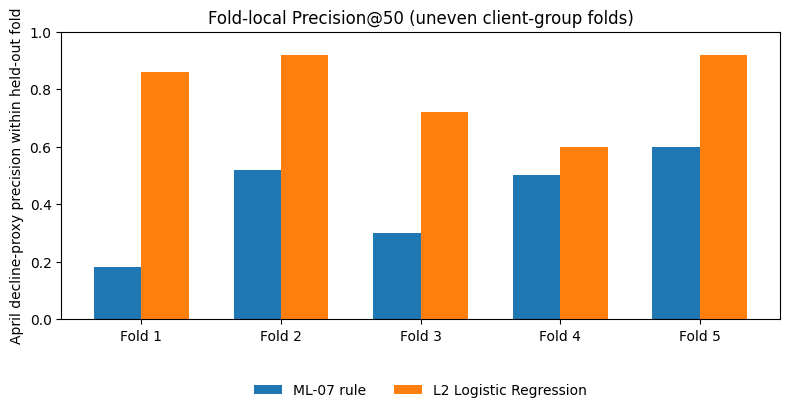

,Recommended action,Candidates
0,review_snippet_and_search_intent,29932
1,review_query_page_fit_and_internal_links,8412
2,verify_coverage_before_edit,1201


Aggregate-only fold figure saved to work\figures\capstone_fold_precision_at_50.png


In [4]:
figures_dir = repo_root / 'work' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(fold_metrics)); width = 0.34
ax.bar(x-width/2, fold_metrics['rule_p_at_50'], width, label='ML-07 rule')
ax.bar(x+width/2, fold_metrics['model_p_at_50'], width, label='L2 Logistic Regression')
ax.set_xticks(x, [f'Fold {n}' for n in fold_metrics['fold']]); ax.set_ylim(0,1)
ax.set_ylabel('April decline-proxy precision within held-out fold')
ax.set_title('Fold-local Precision@50 (uneven client-group folds)')
ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5,-0.18)); fig.subplots_adjust(bottom=0.25); fig.tight_layout(rect=[0,0.06,1,1])
fold_figure = figures_dir / 'capstone_fold_precision_at_50.png'
fig.savefig(fold_figure, dpi=160, bbox_inches='tight'); plt.show(); plt.close(fig)

coverage = candidates['gsc_days_mar'] < 25
page_one = candidates['avg_position_mar'] <= 10
candidates['recommended_action'] = np.select([coverage,page_one], ['verify_coverage_before_edit','review_snippet_and_search_intent'], default='review_query_page_fit_and_internal_links')
actions = candidates['recommended_action'].value_counts().rename_axis('Recommended action').reset_index(name='Candidates')
display(actions)
print(f'Aggregate-only fold figure saved to {fold_figure.relative_to(repo_root)}')

## 5. Ranked recommendations for human review

1. **Verify observation coverage before editing** for partial-observation candidates. Confirm the page and GSC data are current; sparse observation is not proof of decay.
2. **Review snippet and search intent** for page-one low-CTR candidates. Check query mix, SERP features, title/snippet fit, and facts before proposing a change.
3. **Review query-page fit and internal links** for striking-distance low-CTR candidates. Confirm intent alignment and internal discovery context before deciding whether an edit is appropriate.

These are triage actions from W07’s rule-based archetypes, not predicted treatment effects. Do not automatically publish, delete, redirect, canonicalize, or noindex from a score.

## 6. Reproducibility and limitations

Python 3.11; seed 42; median imputation and standard scaling are fit within each training fold. The March and April warehouse partitions are read directly using the ignored repository `.env`; the token is never printed or saved. IDs are used only for joins and client grouping. No April value or label-derived field is used as a predictor. Notebook displays and figures contain aggregates only; the row-level action queue is not shown or exported here.

Run from the repository root using the Python 3.11 environment and execute this notebook top to bottom. Figures are written to `work/figures/`.

The paired cohort requires at least 20 GSC-available days in March and April; April availability is not a feature, but the exact retrospective cohort is not knowable at a March-time decision point. This is not a live March queue or early-warning test. The outcome is an observed month-over-month impression-decline proxy. The analysis does not establish early-warning ability, causal impact, or traffic recovery from refreshes. It covers only the ML-07-selected pool with adequate GSC coverage, uses one temporal cohort, and has uneven client-group folds without an independent later-period cohort. The score is not calibrated. Current page content, query intent, conversions, business value, page age, and refresh timestamps are absent.